# Task 3 (Reproduction): TwinLiteNet+ on BDD100K

Reproducing **TwinLiteNet+** (dual-head Drivable Area + Lane Line segmentation at `640x384` letterbox) across official weights (`nano/small/medium/large`) and an 8-epoch CPU scratch run (`small`).

In [2]:
import os, sys, json
from pathlib import Path
from types import SimpleNamespace
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

CWD = Path(".").resolve()
REPO_ROOT = next((p for p in [Path(".").resolve()] + list(Path(".").resolve().parents) if (p / "TwinLiteNetPlus").exists()), Path(".").resolve())
TL_DIR = REPO_ROOT / "TwinLiteNetPlus"
if str(TL_DIR) not in sys.path:
    sys.path.insert(0, str(TL_DIR))

from model.model import TwinLiteNetPlus
from benchmarks import get_hardware_info, profile_parameters, profile_flops, benchmark_inference_speed
from train_bdd100k import BDD100KMultiTaskDataset, run_training, plot_training_history
from test_bdd100k import evaluate_checkpoint, eval_all_official

DATA_ROOT = TL_DIR / "data" / "bdd100k"
HYP_PATH = TL_DIR / "hyperparameters" / "twinlitev2_hyper.yaml"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")

Device: cpu | PyTorch: 2.14.0+cpu


## 1. Model Variants, Complexity & Speed

In [3]:
hw_info = get_hardware_info(device)
print("Hardware:", hw_info["CPU_Processor"])

paper_refs = {
    "nano": (0.03, 0.57), "small": (0.12, 1.40), "medium": (0.48, 4.63), "large": (1.94, 17.58),
}
dummy = torch.randn(1, 3, 384, 640, device=device)
rows = []
for cfg in ["nano", "small", "medium", "large"]:
    m = TwinLiteNetPlus(SimpleNamespace(config=cfg)).to(device).eval()
    with torch.no_grad():
        da, ll = m(dummy)
    p = profile_parameters(m)
    fl = profile_flops(m, [(384, 640)], device=device)[0]
    sp = benchmark_inference_speed(m, input_resolution=(384, 640), batch_size=1, device=device, warmup_runs=3, timed_runs=10)
    rows.append({
        "Config": cfg, "DA / LL Shape": f"{tuple(da.shape)}",
        "Params (M)": round(p["total_params_M"], 3), "Paper Params": paper_refs[cfg][0],
        "FLOPs (G)": round(fl["FLOPs_G"], 2), "Paper MACs (G)": paper_refs[cfg][1],
        "CPU ms": round(sp["Mean_Latency_ms"], 1), "CPU FPS": round(sp["FPS"], 2),
    })
display(pd.DataFrame(rows))

Hardware: Intel64 Family 6 Model 154 Stepping 4, GenuineIntel


c:\Users\gitan\miniconda3\Lib\site-packages\thop\vision\calc_func.py:53: UserWarning: This API is being deprecated
  warnings.warn("This API is being deprecated")


,Config,DA / LL Shape,Params (M),Paper Params,FLOPs (G),Paper MACs (G),CPU ms,CPU FPS
0,nano,"(1, 2, 384, 640)",0.033,0.03,1.13,0.57,60.6,16.49
1,small,"(1, 2, 384, 640)",0.122,0.12,2.80,1.40,49.9,20.02
2,medium,"(1, 2, 384, 640)",0.479,0.48,9.26,4.63,113.6,8.80
3,large,"(1, 2, 384, 640)",1.944,1.94,35.17,17.58,629.5,1.59


## 2. Official Checkpoints on BDD100K (N=250 Val Scenes)

In [4]:
official_dir = REPO_ROOT / "output" / "bdd100k_twinlitenetplus_official"
official_json = official_dir / "official_bdd100k_comparison.json"

official_rows = json.loads(official_json.read_text()) if official_json.exists() else eval_all_official(
    data_root=str(DATA_ROOT), pretrained_dir=str(TL_DIR / "pretrained"), output_dir=str(official_dir)
)
paper_acc = {
    "nano": (87.3, 70.2, 23.3), "small": (90.6, 75.8, 29.3),
    "medium": (92.0, 79.1, 32.3), "large": (92.9, 81.9, 34.2),
}
df_off = pd.DataFrame(official_rows)
df_off["Paper DA mIoU"] = [paper_acc[r["Config"]][0] for r in official_rows]
df_off["Paper LL Acc"] = [paper_acc[r["Config"]][1] for r in official_rows]
df_off["Paper LL IoU"] = [paper_acc[r["Config"]][2] for r in official_rows]
display(df_off[["Config", "Params_M", "DA_mIoU_percent", "Paper DA mIoU", "LL_Accuracy_percent", "Paper LL Acc", "LL_IoU_percent", "Paper LL IoU"]])

,Config,Params_M,DA_mIoU_percent,Paper DA mIoU,LL_Accuracy_percent,Paper LL Acc,LL_IoU_percent,Paper LL IoU
0,nano,0.033,87.67,87.3,70.34,70.2,19.38,23.3
1,small,0.122,90.81,90.6,76.27,75.8,23.77,29.3
2,medium,0.479,91.81,92.0,79.44,79.1,25.80,32.3
3,large,1.944,92.69,92.9,82.24,81.9,26.91,34.2


## 3. Training (`small`, 8 Epochs CPU Scratch)

TWINLITENET+ (SMALL) TRAINING ON BDD100K
[INFO] Device: cpu | Config: small | LR: 0.001 | Epochs: 20
[INFO] Train images: 400 | Val images: 250


[Epoch 1/20] Loss: 1.1807 (Focal: 0.3437, Tversky: 0.8370) | DA mIoU: 57.09% | LL Acc: 52.19% | LL IoU: 1.10% | 251.3s


[Epoch 2/20] Loss: 0.9096 (Focal: 0.2267, Tversky: 0.6829) | DA mIoU: 64.79% | LL Acc: 54.48% | LL IoU: 2.10% | 233.1s


[Epoch 3/20] Loss: 0.7620 (Focal: 0.1494, Tversky: 0.6126) | DA mIoU: 72.97% | LL Acc: 52.18% | LL IoU: 2.92% | 261.0s


[Epoch 4/20] Loss: 0.6887 (Focal: 0.1140, Tversky: 0.5747) | DA mIoU: 72.39% | LL Acc: 54.04% | LL IoU: 4.59% | 263.2s


[Epoch 5/20] Loss: 0.6382 (Focal: 0.0944, Tversky: 0.5437) | DA mIoU: 72.68% | LL Acc: 55.42% | LL IoU: 4.37% | 262.1s


... (11 outputs left out)

[Epoch 17/20] Loss: 0.4341 (Focal: 0.0658, Tversky: 0.3682) | DA mIoU: 78.27% | LL Acc: 67.23% | LL IoU: 10.29% | 259.9s


[Epoch 18/20] Loss: 0.4256 (Focal: 0.0655, Tversky: 0.3601) | DA mIoU: 78.63% | LL Acc: 66.08% | LL IoU: 10.58% | 259.3s


[Epoch 19/20] Loss: 0.4267 (Focal: 0.0654, Tversky: 0.3613) | DA mIoU: 77.85% | LL Acc: 65.36% | LL IoU: 10.60% | 261.5s


[Epoch 20/20] Loss: 0.4143 (Focal: 0.0647, Tversky: 0.3496) | DA mIoU: 78.51% | LL Acc: 64.67% | LL IoU: 10.71% | 118.4s
[INFO] Plot saved to: C:\Users\gitan\Desktop\AI Project\output\bdd100k_twinlitenetplus_train\loss_vs_epoch.png


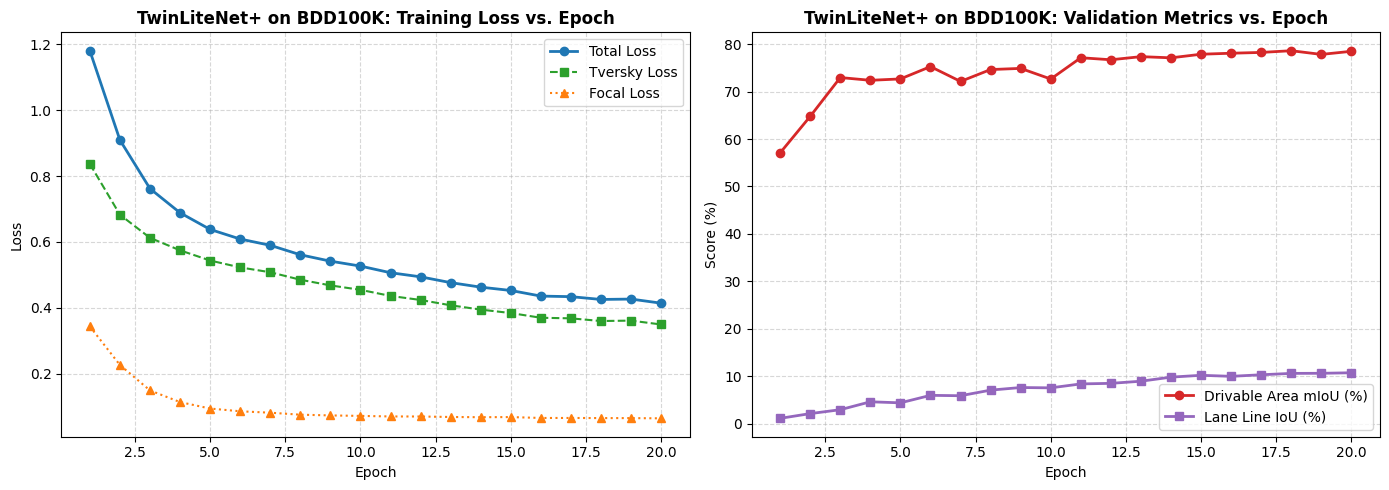

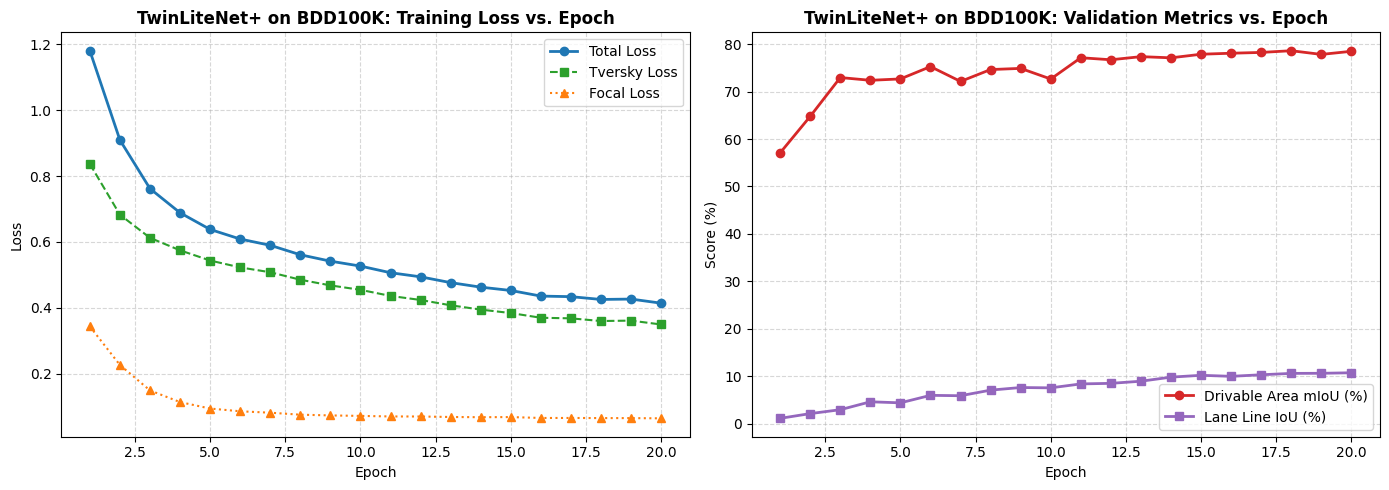

In [9]:
TRAIN_CONFIG = {
    "model_config": "small",
    "epochs": 20,
    "batch_size": 2,
    "base_lr": 0.001,
    "save_dir": str(REPO_ROOT / "output" / "bdd100k_twinlitenetplus_train"),
}

RETRAIN = True  # Set True to re-run training
hist_path = Path(TRAIN_CONFIG["save_dir"]) / "training_history.json"
best_ckpt = Path(TRAIN_CONFIG["save_dir"]) / f"best_twinlitenetplus_{TRAIN_CONFIG['model_config']}_bdd100k.pth"

if RETRAIN or not (hist_path.exists() and best_ckpt.exists()):
    history = run_training(
        data_root=str(DATA_ROOT), hyp_path=str(HYP_PATH),
        model_config=TRAIN_CONFIG["model_config"], epochs=TRAIN_CONFIG["epochs"],
        batch_size=TRAIN_CONFIG["batch_size"], base_lr=TRAIN_CONFIG["base_lr"], save_dir=TRAIN_CONFIG["save_dir"],
    )
else:
    history = json.loads(hist_path.read_text())
    print(f"Loaded {len(history)}-epoch history from {hist_path.name}")

plot_training_history(history)
plt.show()

## 4. CPU Scratch Evaluation & Sample Predictions

c:\Users\gitan\miniconda3\Lib\site-packages\thop\vision\calc_func.py:53: UserWarning: This API is being deprecated
  warnings.warn("This API is being deprecated")


Config                  small
Samples                   250
Params_M                0.122
FLOPs_G                   2.8
CPU_Latency_ms          57.64
CPU_FPS                 17.35
DA_mIoU_percent         78.51
DA_FG_IoU_percent       65.29
DA_Pixel_Acc_percent    92.85
LL_Accuracy_percent     64.67
LL_IoU_percent          10.71
LL_mIoU_percent         54.57
dtype: object


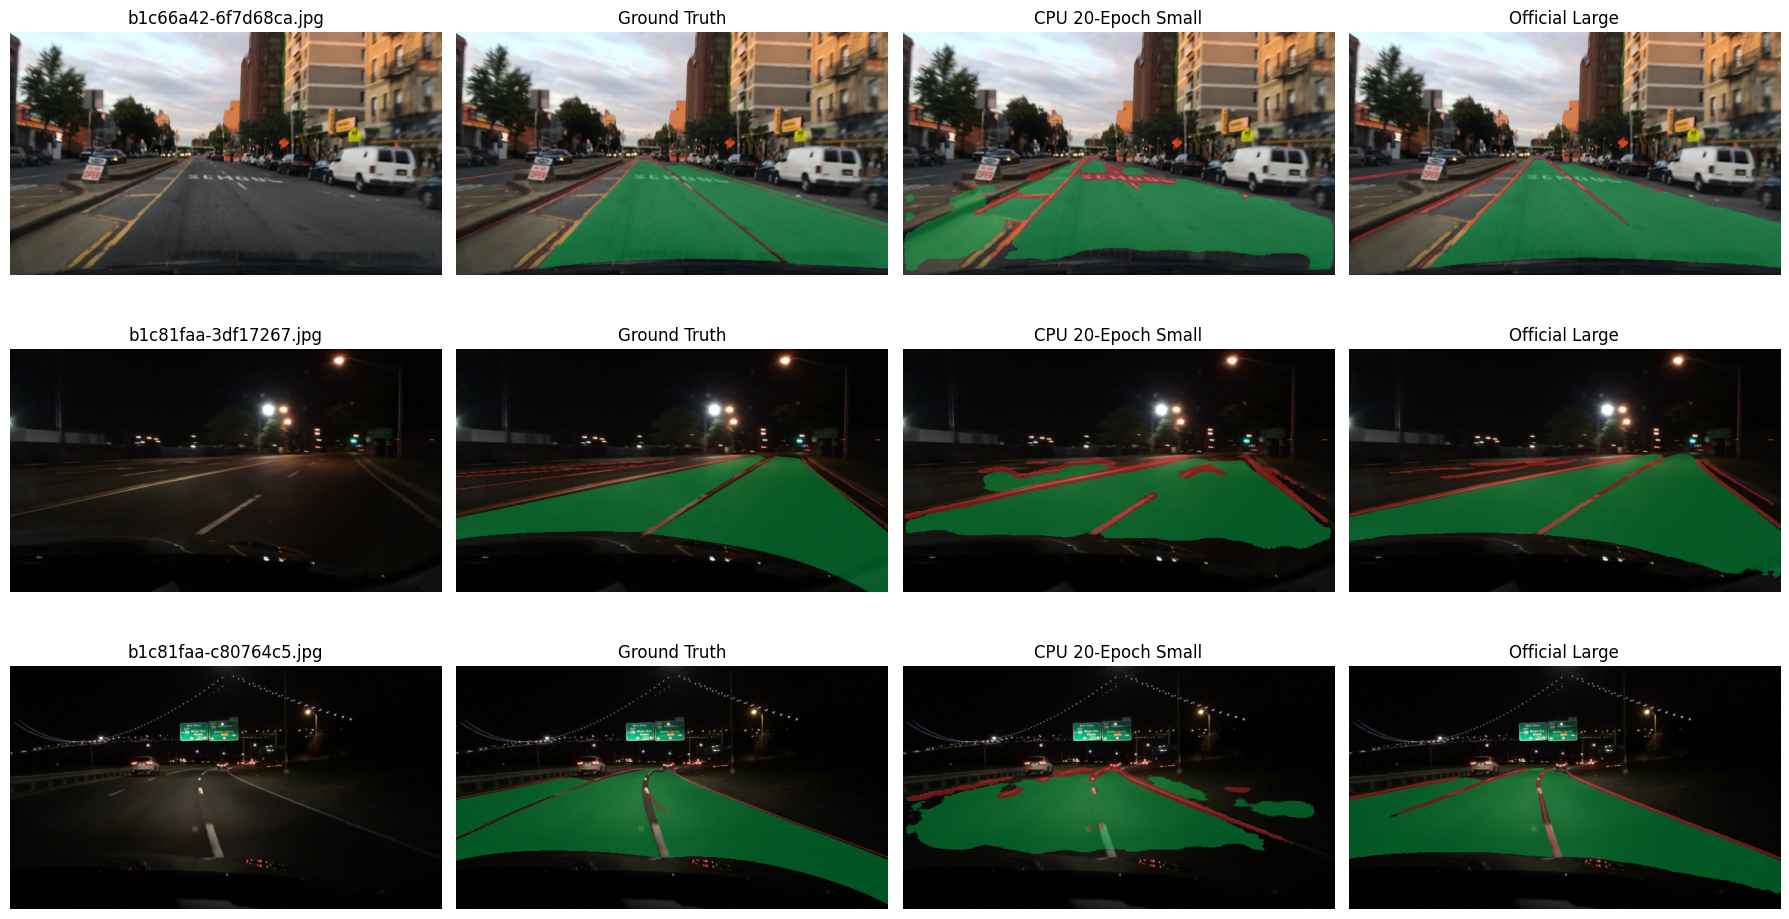

In [10]:
trained_out_dir = REPO_ROOT / "output" / "bdd100k_twinlitenetplus_test"
trained_summary = evaluate_checkpoint(
    data_root=str(DATA_ROOT), hyp_path=str(HYP_PATH),
    model_config=TRAIN_CONFIG["model_config"], weights_path=str(best_ckpt),
    batch_size=4, save_vis_dir=str(trained_out_dir / "overlays"),
)
print(pd.Series(trained_summary))

hyp = yaml.safe_load(open(HYP_PATH, "r", encoding="utf-8"))
val_ds = BDD100KMultiTaskDataset(str(DATA_ROOT), split="val", hyp=hyp, valid=True)
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for i, fname in enumerate(val_ds.names[:3]):
    stem = Path(fname).stem
    _, img_t, gt_da, gt_ll = val_ds[i]
    img_np = (img_t[:, 12:-12, :].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    gt_vis = img_np.copy(); gt_vis[gt_da.numpy() == 1] = [0, 200, 80]; gt_vis[gt_ll.numpy() == 1] = [230, 40, 40]
    gt_blend = (0.58 * img_np + 0.42 * gt_vis).astype(np.uint8)
    cpu_ov = np.array(Image.open(trained_out_dir / "overlays" / f"{stem}_overlay.png"))
    off_ov = np.array(Image.open(official_dir / "vis_large" / f"{stem}_overlay.png"))
    axes[i, 0].imshow(img_np); axes[i, 0].set_title(fname); axes[i, 0].axis("off")
    axes[i, 1].imshow(gt_blend); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
    axes[i, 2].imshow(cpu_ov); axes[i, 2].set_title("CPU 20-Epoch Small"); axes[i, 2].axis("off")
    axes[i, 3].imshow(off_ov); axes[i, 3].set_title("Official Large"); axes[i, 3].axis("off")
plt.tight_layout()
plt.show()

## 5. Paper vs. Reproduction Summary

In [12]:
small_off = next(r for r in official_rows if r["Config"] == "small")
display(pd.DataFrame({
    "Metric": ["DA mIoU (%)", "Lane Line Acc (%)", "Lane Line IoU (%)"],
    "Paper Small (Che et al., 2025)": [90.6, 75.8, 29.3],
    "Official Small (250 val)": [small_off["DA_mIoU_percent"], small_off["LL_Accuracy_percent"], small_off["LL_IoU_percent"]],
    "CPU 20-Ep Scratch Small": [trained_summary["DA_mIoU_percent"], trained_summary["LL_Accuracy_percent"], trained_summary["LL_IoU_percent"]],
}))

,Metric,"Paper Small (Che et al., 2025)",Official Small (250 val),CPU 20-Ep Scratch Small
0,DA mIoU (%),90.6,90.81,78.51
1,Lane Line Acc (%),75.8,76.27,64.67
2,Lane Line IoU (%),29.3,23.77,10.71
